# Machine Learning Demand Forecasting: Model Development & Evaluation
## Algions AI Labs Assessment: Pharmacy Medicine Demand & Expiry-Risk

### 1. Problem Formulation & Split Strategy
- **Prediction Target**: Daily unit sales $y_t$ for each therapeutic drug category.
- **Forecast Horizons**: 7 days (weekly replenishment), 30 days (monthly cycle), 90 days (quarterly procurement).
- **Split Strategy**: Strict **chronological split**:
  - Train Set: 2014-02-01 to 2018-12-31 (1,795 days, ~86%)
  - Held-out Test Set: 2019-01-01 to 2019-10-08 (281 days, ~14%)
  - Strictly zero shuffling to prevent future-looking target leakage.
- **Evaluation Metrics**:
  - **MAE** (Mean Absolute Error): Average unit deviation.
  - **RMSE** (Root Mean Squared Error): Penalizes larger forecasting errors.
  - **WAPE** (Weighted Absolute Percentage Error): $\frac{\sum |y_i - \hat{y}_i|}{\sum y_i} \times 100\%$, indispensable for zero-sales intervals where MAPE is mathematically undefined.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Load model metrics from training run
with open('../saved_models/model_metrics.json', 'r') as f:
    metrics = json.load(f)

# Display metrics across all categories
rows = []
for cat, data in metrics.items():
    best = data.get('best_model')
    for m_name in ['Baseline_30d_MA', 'Ridge_Regression', 'Random_Forest', 'XGBoost']:
        m_data = data[m_name]
        rows.append({
            'Category': cat,
            'Model': m_name,
            'MAE': m_data['MAE'],
            'RMSE': m_data['RMSE'],
            'WAPE (%)': m_data['WAPE_percent'],
            'Is Best': '★' if m_name == best else ''
        })
metrics_df = pd.DataFrame(rows)
metrics_df.head(12)

,Category,Model,MAE,RMSE,WAPE (%),Is Best
0,M01AB,Baseline_30d_MA,2.248,2.899,41.64,
1,M01AB,Ridge_Regression,2.210,2.844,40.93,★
2,M01AB,Random_Forest,2.242,2.895,41.52,
3,M01AB,XGBoost,2.274,2.891,42.11,
4,M01AE,Baseline_30d_MA,1.761,2.300,45.64,
5,M01AE,Ridge_Regression,1.652,2.168,42.80,★
6,M01AE,Random_Forest,1.722,2.230,44.61,
7,M01AE,XGBoost,1.736,2.240,44.98,
8,N02BA,Baseline_30d_MA,1.500,1.932,47.91,
9,N02BA,Ridge_Regression,1.475,1.916,47.12,★


### 2. Model Performance Comparison Across Categories
Comparing WAPE error reduction between the simple 30-day Moving Average baseline and the trained machine learning models.


<Figure size 1200x600 with 0 Axes>

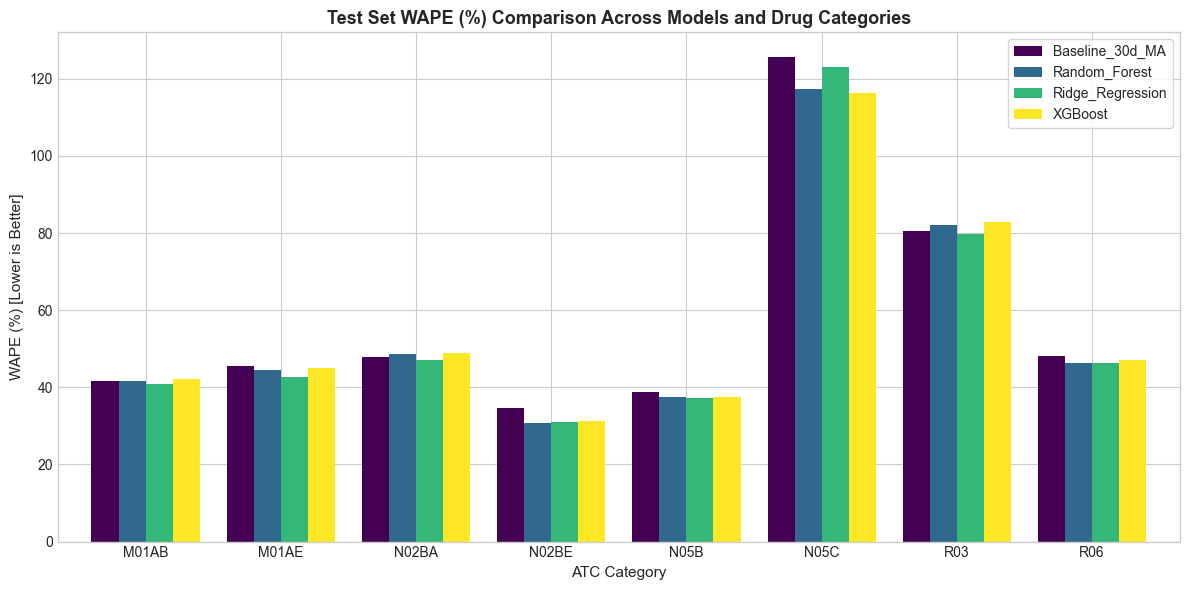

In [2]:
pivot_wape = metrics_df.pivot(index='Category', columns='Model', values='WAPE (%)')
plt.figure(figsize=(12, 6))
pivot_wape.plot(kind='bar', figsize=(12, 6), colormap='viridis', width=0.8)
plt.title('Test Set WAPE (%) Comparison Across Models and Drug Categories', fontsize=13, fontweight='bold')
plt.ylabel('WAPE (%) [Lower is Better]', fontsize=11)
plt.xlabel('ATC Category', fontsize=11)
plt.xticks(rotation=0)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### 3. Actual vs Predicted Demand on Held-Out 2019 Test Set
Inspecting the high-volume category `N02BE` (Anilides / Paracetamol) across the 281-day held-out test evaluation window.


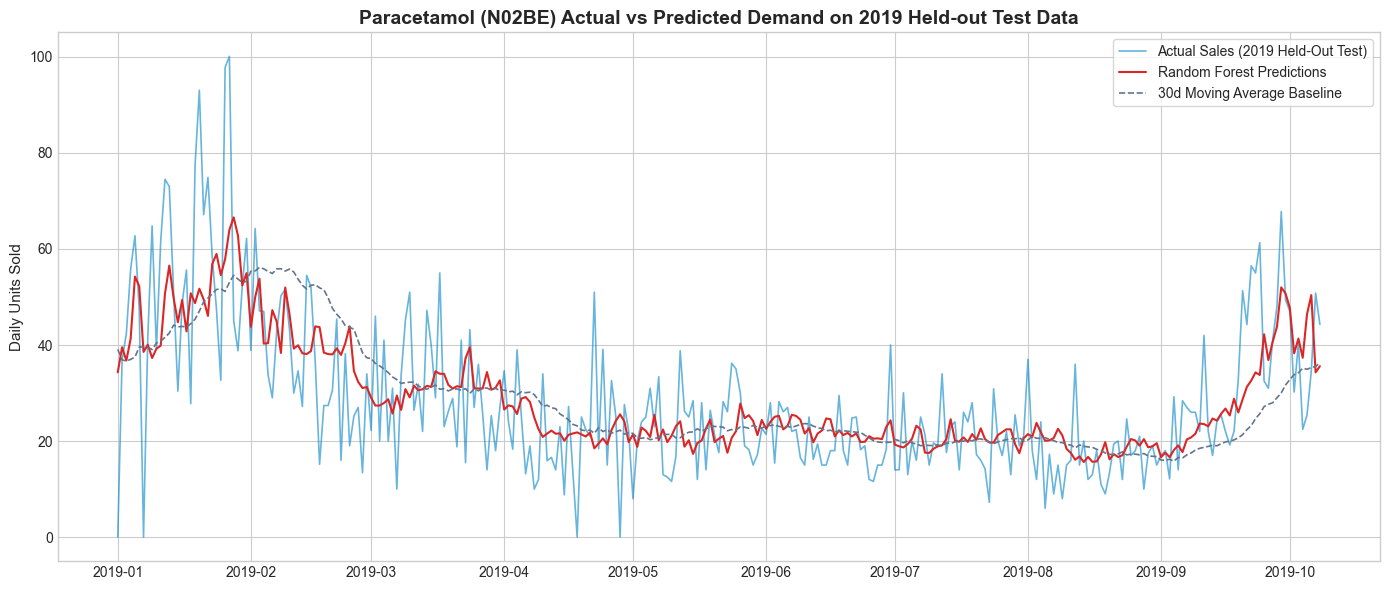

In [3]:
import joblib

# Load engineered features
df = pd.read_csv('../../dataset/processed/engineered_features.csv', index_col=0)
df.index = pd.to_datetime(df.index)
test_df = df[df.index >= '2019-01-01'].copy()

# Load trained model for N02BE
model_obj = joblib.load('../saved_models/demand_N02BE_random_forest.joblib')
model = model_obj['model']
features = model_obj['feature_names']

X_test = test_df[features]
test_df['predicted_sales'] = np.clip(model.predict(X_test), 0, None)

plt.figure(figsize=(14, 6))
plt.plot(test_df.index, test_df['N02BE_target'], label='Actual Sales (2019 Held-Out Test)', color='#0284c7', alpha=0.6, linewidth=1.2)
plt.plot(test_df.index, test_df['predicted_sales'], label='Random Forest Predictions', color='#dc2626', linewidth=1.5)
plt.plot(test_df.index, test_df['N02BE_rolling_mean_30'], label='30d Moving Average Baseline', color='#64748b', linestyle='--', linewidth=1.2)
plt.title('Paracetamol (N02BE) Actual vs Predicted Demand on 2019 Held-out Test Data', fontsize=14, fontweight='bold')
plt.ylabel('Daily Units Sold', fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### 4. Residual and Error Analysis
Analysis of prediction residuals $(y - \hat{y})$ to confirm lack of systemic bias and verify normal distribution of errors.


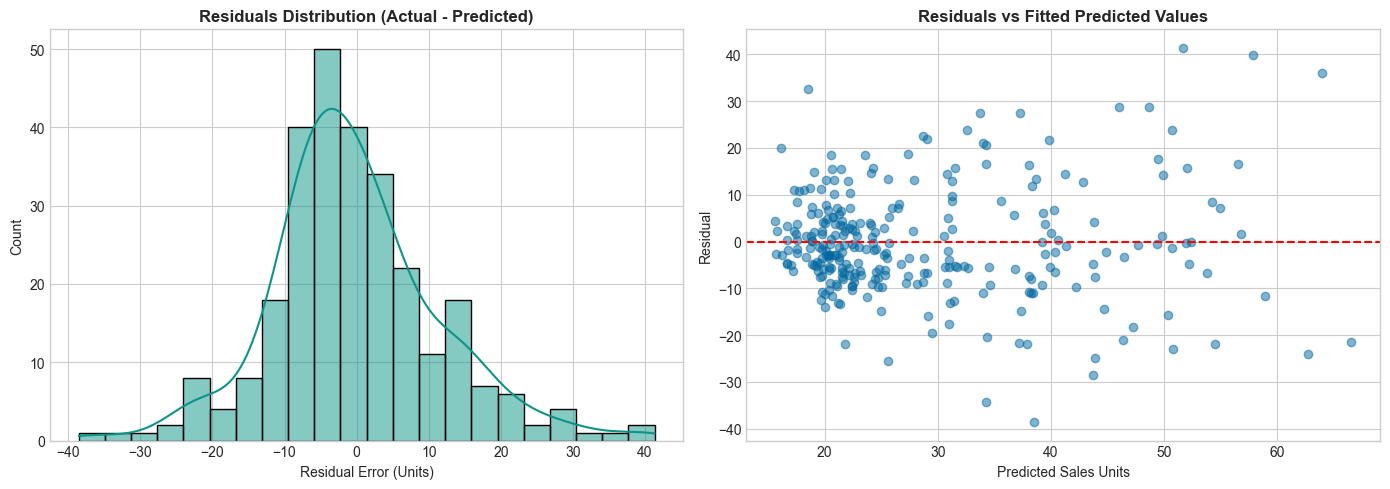

Mean Residual: -0.281 (Near zero indicates unbiased prediction)
Std Deviation of Residuals: 11.716


In [4]:
residuals = test_df['N02BE_target'] - test_df['predicted_sales']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, kde=True, ax=ax1, color='#0d9488')
ax1.set_title('Residuals Distribution (Actual - Predicted)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Residual Error (Units)')

ax2.scatter(test_df['predicted_sales'], residuals, alpha=0.5, color='#0369a1')
ax2.axhline(0, color='red', linestyle='--')
ax2.set_title('Residuals vs Fitted Predicted Values', fontsize=12, fontweight='bold')
ax2.set_xlabel('Predicted Sales Units')
ax2.set_ylabel('Residual')

plt.tight_layout()
plt.show()
print(f'Mean Residual: {residuals.mean():.3f} (Near zero indicates unbiased prediction)')
print(f'Std Deviation of Residuals: {residuals.std():.3f}')

### 5. Decision-Support Advisory Declaration
> **IMPORTANT**: This forecasting model is an **operational decision-support tool** designed to assist inventory managers with procurement orders and safety stock planning. Forecasts reflect statistical trends and historical sales patterns; they do **not** constitute medical advice, prescribing guidance, or clinical treatment recommendations.